## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler


We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [2]:
ames = pd.read_csv('https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt', sep='\t')
good_cols = ames.isna().sum() < 100
ames = ames.loc[:, good_cols]
ames = ames.dropna()
X = ames.drop(['SalePrice', 'Order', 'PID'], axis=1)
y = ames['SalePrice']
print(X.head().to_string())


   MS SubClass MS Zoning  Lot Area Street Lot Shape Land Contour Utilities Lot Config Land Slope Neighborhood Condition 1 Condition 2 Bldg Type House Style  Overall Qual  Overall Cond  Year Built  Year Remod/Add Roof Style Roof Matl Exterior 1st Exterior 2nd  Mas Vnr Area Exter Qual Exter Cond Foundation Bsmt Qual Bsmt Cond Bsmt Exposure BsmtFin Type 1  BsmtFin SF 1 BsmtFin Type 2  BsmtFin SF 2  Bsmt Unf SF  Total Bsmt SF Heating Heating QC Central Air Electrical  1st Flr SF  2nd Flr SF  Low Qual Fin SF  Gr Liv Area  Bsmt Full Bath  Bsmt Half Bath  Full Bath  Half Bath  Bedroom AbvGr  Kitchen AbvGr Kitchen Qual  TotRms AbvGrd Functional  Fireplaces  Garage Cars  Garage Area Paved Drive  Wood Deck SF  Open Porch SF  Enclosed Porch  3Ssn Porch  Screen Porch  Pool Area  Misc Val  Mo Sold  Yr Sold Sale Type Sale Condition
0           20        RL     31770   Pave       IR1          Lvl    AllPub     Corner        Gtl        NAmes        Norm        Norm      1Fam      1Story             6 

In [3]:
print(y.head().to_string())


0    215000
1    105000
2    172000
3    244000
4    189900


Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [4]:
ct = ColumnTransformer([('dummify', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), make_column_selector(dtype_include=object)), ('standardize', StandardScaler(), make_column_selector(dtype_include=np.number))], remainder='passthrough').set_output(transform='pandas')


In [5]:
lr_pipeline = Pipeline([('preprocessing', ct), ('linear_regression', LinearRegression())])


In [6]:
lr_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


Now let's use cross-validation to evaluate based on $R^2$.

In [7]:
cv_scores = cross_val_score(lr_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[0.88433686 0.90316706 0.87507511 0.91216037 0.82269502 0.73890838
 0.86879893 0.63798647 0.90277443 0.90350125]
Mean CV R-squared: 0.845


Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [8]:
numeric_poly = Pipeline([('polynomial_features', PolynomialFeatures(degree=2)), ('standardize', StandardScaler())])
ct_poly = ColumnTransformer([('dummify', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), make_column_selector(dtype_include=object)), ('numeric_poly', numeric_poly, make_column_selector(dtype_include=np.number))], remainder='drop').set_output(transform='pandas')


In [9]:
poly_pipeline = Pipeline([('preprocessing', ct_poly), ('linear_regression', LinearRegression())])


In [10]:
poly_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


In [11]:
cv_scores = cross_val_score(poly_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[ 0.88322049 -0.2351045  -5.18937934  0.53298354 -1.81034894  0.65934136
  0.23955858 -1.0532801  -3.71975499  0.31162845]
Mean CV R-squared: -0.938


OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through many possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work?

Least squares chooses the slope and intercept that minimize the sum of squared differences between actual and predicted sale prices.

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case?

It chooses both slopes and the intercept together to minimize the sum of squared prediction errors. Each slope accounts for the other predictor.

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to?

Living area is about $136 per additional square foot, holding bedrooms fixed. Bedrooms is about -$29,132 per additional bedroom, holding area fixed. The coefficients have different units, so their sizes alone do not show which predictor matters more.

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to?

Each coefficient is the predicted dollar change for a one-standard-deviation increase in that predictor, holding the others fixed. Larger absolute coefficients mean greater sensitivity to changes of that size.

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient?

Move its coefficient closer to zero so changes in that variable have less effect on the prediction.

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient?

Set its coefficient to zero.

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0?

The model now minimizes prediction error plus a penalty on coefficient size. Smaller coefficients reduce the penalty, so the fit trades off accuracy on the training data against coefficient size.

8. Why is it important to standarize variables when using a penalty?

Without standardizing, the penalty depends on the units of each predictor. Standardizing puts numeric predictors on a comparable scale so the penalty is fairer.

9. What happens if the penalty parameter $\lambda$ is 0?

There is no penalty, so the objective becomes ordinary least squares.

10. What happens as the penalty parameter $\lambda$ gets larger and larger?

The coefficients shrink more as the penalty grows. LASSO can set them exactly to zero, while ridge usually moves them toward zero. With a very large penalty, predictions approach the mean response.

11. Why do we not penalize the intercept?

The intercept sets the baseline prediction. Penalizing it would pull predictions toward zero even when the response has a different mean.

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely?

LASSO adds |0.1| = 0.1, while ridge adds 0.1 squared = 0.01. Setting the coefficient to zero reduces the penalties by 0.1 and 0.01, respectively. LASSO gives the larger payoff for removing a small coefficient.

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [12]:
ridge_pipeline = Pipeline([('preprocessing', ct), ('ridge_regression', Ridge(alpha=1))])


In [13]:
ridge_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


In [14]:
cv_scores = cross_val_score(ridge_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[0.88714414 0.90234101 0.87838221 0.92163172 0.8345624  0.74313152
 0.86135562 0.68453605 0.91776347 0.90466508]
Mean CV R-squared: 0.854


There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [15]:
coef_compare = pd.DataFrame()
coef_compare['feature'] = lr_pipeline.named_steps['preprocessing'].get_feature_names_out()
coef_compare['lr'] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare['ridge'] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare['diff'] = abs(coef_compare['lr']) - abs(coef_compare['ridge'])


In [16]:
print(coef_compare.sort_values(by='diff', ascending=False).head(20).to_string())


                           feature             lr          ridge           diff
91      dummify__Roof Matl_ClyTile -559653.342134 -233156.089658  326497.252476
93      dummify__Roof Matl_Membran  119504.966230   32582.552859   86922.413371
94        dummify__Roof Matl_Metal  109059.255835   28387.663156   80671.592679
37   dummify__Neighborhood_GrnHill  127054.304996   66530.685838   60523.619159
69       dummify__Condition 2_RRAe   64910.291903   24567.527777   40342.764126
95         dummify__Roof Matl_Roll   55399.766568   16828.505080   38571.261487
96      dummify__Roof Matl_Tar&Grv   61103.839805   24715.717943   36388.121863
68       dummify__Condition 2_PosN -113384.181772  -77996.160321   35388.021451
98      dummify__Roof Matl_WdShngl  118966.036255   83910.181360   35055.854896
97      dummify__Roof Matl_WdShake   47803.911563   19929.205625   27874.705939
92      dummify__Roof Matl_CompShg   47815.565877   26802.263636   21013.302241
106  dummify__Exterior 1st_ImStucc  -338

Let's add a ridge penalty to the polynomial regression

In [17]:
ridge_poly_pipeline = Pipeline([('preprocessing', ct_poly), ('ridge_regression', Ridge(alpha=1))])


In [18]:
ridge_poly_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


In [19]:
cv_scores = cross_val_score(ridge_poly_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[ 0.91643374  0.91589548  0.52803531  0.84083074  0.78663152  0.68627357
  0.85705628 -0.04182712  0.419092    0.83885314]
Mean CV R-squared: 0.675


In [20]:
poly_coef_compare = pd.DataFrame()
poly_coef_compare['feature'] = poly_pipeline.named_steps['preprocessing'].get_feature_names_out()
poly_coef_compare['lr_poly'] = poly_pipeline.named_steps['linear_regression'].coef_
poly_coef_compare['ridge_poly'] = ridge_poly_pipeline.named_steps['ridge_regression'].coef_
poly_coef_compare['diff_poly'] = poly_coef_compare['lr_poly'].abs() - poly_coef_compare['ridge_poly'].abs()


In [21]:
print(poly_coef_compare.sort_values(by='diff_poly', ascending=False).head(20).to_string())


                                    feature       lr_poly   ridge_poly     diff_poly
794       numeric_poly__Garage Cars Yr Sold  3.387006e+06 -4620.485750  3.382386e+06
244               numeric_poly__Garage Cars -3.245972e+06 -5390.912549  3.240581e+06
834        numeric_poly__3Ssn Porch Yr Sold -3.033907e+06  2595.063963  3.031312e+06
804       numeric_poly__Garage Area Yr Sold -2.974090e+06 -4376.452692  2.969713e+06
245               numeric_poly__Garage Area  2.798078e+06 -4469.165800  2.793609e+06
596        numeric_poly__1st Flr SF Yr Sold -2.218177e+06 -7416.039184  2.210761e+06
239                 numeric_poly__Half Bath  2.102007e+06   411.776837  2.101596e+06
729         numeric_poly__Half Bath Yr Sold -2.048068e+06   189.821063  2.047878e+06
639   numeric_poly__Low Qual Fin SF Yr Sold  2.003155e+06  -847.815488  2.002308e+06
232                numeric_poly__1st Flr SF  1.920272e+06 -6833.772255  1.913438e+06
234           numeric_poly__Low Qual Fin SF -1.865238e+06  -874.7

## LASSO

Now let's try LASSO

In [22]:
lasso_pipeline = Pipeline([('preprocessing', ct), ('lasso_regression', Lasso(alpha=1, max_iter=50000, tol=0.01, precompute=True))])


In [23]:
lasso_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


In [24]:
cv_scores = cross_val_score(lasso_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[0.88516636 0.90347849 0.87606098 0.91273859 0.84054117 0.74896969
 0.87212503 0.63874636 0.9033984  0.91475016]
Mean CV R-squared: 0.850


In [25]:
coef_compare['lasso'] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare['ridge_lasso_diff'] = abs(coef_compare['ridge']) - abs(coef_compare['lasso'])


In [26]:
print(coef_compare.sort_values(by='ridge_lasso_diff', ascending=False).head(20).to_string())


                           feature             lr         ridge          diff         lasso  ridge_lasso_diff
126  dummify__Exterior 2nd_PreCast   37584.951869  25708.646790  11876.305079  2.318400e+02      25476.806792
98      dummify__Roof Matl_WdShngl  118966.036255  83910.181360  35055.854896  5.881424e+04      25095.942547
96      dummify__Roof Matl_Tar&Grv   61103.839805  24715.717943  36388.121863  0.000000e+00      24715.717943
95         dummify__Roof Matl_Roll   55399.766568  16828.505080  38571.261487 -9.500078e+02      15878.497320
92      dummify__Roof Matl_CompShg   47815.565877  26802.263636  21013.302241 -1.158842e+04      15213.842272
234       standardize__Gr Liv Area   16600.094435  16145.164414    454.930021  4.621088e+03      11524.076097
10          dummify__Lot Shape_IR3    -169.659499 -10864.716766 -10695.057267  4.714716e+02      10393.245130
7             dummify__Street_Pave   10466.885622   9333.963950   1132.921672  2.642348e-08       9333.963950
97      du

How many ridge coefficients are 0?

In [27]:
print((coef_compare['ridge'] == 0).sum())


0


How many LASSO coefficients are 0?

In [28]:
print((coef_compare['lasso'] == 0).sum())


24


Let's add a lasso penalty to the polynomial regression

In [29]:
lasso_poly_pipeline = Pipeline([('preprocessing', ct_poly), ('lasso_regression', Lasso(alpha=1, max_iter=50000, tol=0.01, precompute=True))])


In [30]:
lasso_poly_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


In [31]:
cv_scores = cross_val_score(lasso_poly_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[ 0.89999708  0.82750827  0.47754445  0.84071266  0.76755168  0.69038918
  0.82730155 -0.29466125  0.34550945  0.86086472]
Mean CV R-squared: 0.624


In [32]:
poly_coef_compare['lasso_poly'] = lasso_poly_pipeline.named_steps['lasso_regression'].coef_
poly_coef_compare['ridge_lasso_diff_poly'] = poly_coef_compare['ridge_poly'].abs() - poly_coef_compare['lasso_poly'].abs()


In [33]:
print(poly_coef_compare.sort_values(by='ridge_lasso_diff_poly', ascending=False).head(20).to_string())


                                     feature       lr_poly    ridge_poly     diff_poly    lasso_poly  ridge_lasso_diff_poly
126            dummify__Exterior 2nd_PreCast  4.650862e+04  26111.675137  2.039694e+04   1135.584010           24976.091126
302       numeric_poly__Lot Area Gr Liv Area -2.634934e+04 -22033.486849  4.315854e+03  -8598.150096           13435.336753
334   numeric_poly__Overall Qual Gr Liv Area  5.111578e+03  11990.016265 -6.878439e+03     -0.000000           11990.016265
648     numeric_poly__Gr Liv Area Fireplaces  1.057487e+04   9014.119197  1.560754e+03      0.000000            9014.119197
647  numeric_poly__Gr Liv Area TotRms AbvGrd -1.485614e+04  -8888.463360  5.967672e+03   -762.775223            8125.688137
640              numeric_poly__Gr Liv Area^2 -1.045107e+04  -8026.279029  2.424791e+03      0.000000            8026.279029
238                  numeric_poly__Full Bath  6.294234e+05  -7717.593345  6.217058e+05     -0.000000            7717.593345
98      

How many ridge coefficients are 0?

In [34]:
print((poly_coef_compare['ridge_poly'] == 0).sum())


4


How many LASSO coefficients are 0?

In [35]:
print((poly_coef_compare['lasso_poly'] == 0).sum())


167


## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [36]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline([('preprocessing', ct), ('lasso_regression', Lasso(alpha=1, max_iter=50000, tol=0.01, precompute=True))]).set_output(transform='pandas')
alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}
gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv=10, scoring='r2')


In [37]:
gscv_fitted = gscv.fit(X, y)
print('Best parameters:', gscv_fitted.best_params_)
print(f'Best CV R-squared: {gscv_fitted.best_score_:.3f}')


Best parameters: {'lasso_regression__alpha': np.int64(100)}
Best CV R-squared: 0.859


In [38]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)
print(df_cv_results_.head(20).to_string())


   mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_lasso_regression__alpha                              params  split0_test_score  split1_test_score  split2_test_score  split3_test_score  split4_test_score  split5_test_score  split6_test_score  split7_test_score  split8_test_score  split9_test_score  mean_test_score  std_test_score  rank_test_score
0       0.092194      0.036321         0.014099        0.005995                          10000  {'lasso_regression__alpha': 10000}           0.772631           0.740895           0.736813           0.792359           0.725877           0.673200           0.768613           0.651087           0.809701           0.764086         0.743526        0.047452                5
1       0.113970      0.041404         0.014236        0.006228                           1000   {'lasso_regression__alpha': 1000}           0.863333           0.871030           0.817430           0.914015           0.833766           0.705659           0.8

## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [39]:
elastic_pipeline = Pipeline([('preprocessing', ct), ('elastic_net', ElasticNet(alpha=1, l1_ratio=0.5, max_iter=50000, tol=0.01))])


In [40]:
cv_scores = cross_val_score(elastic_pipeline, X, y, cv=10, scoring='r2')
print(cv_scores)
print(f'Mean CV R-squared: {cv_scores.mean():.3f}')


[0.85554177 0.8407185  0.8548293  0.88754953 0.85075176 0.72374486
 0.80725471 0.66306537 0.89132068 0.84737827]
Mean CV R-squared: 0.822


In [41]:
elastic_pipeline.fit(X, y)
print('Model fitted.')


Model fitted.


## Elastic Net: Grid search

In [42]:
elastic_pipeline_1 = Pipeline([('preprocessing', ct), ('elastic_net', ElasticNet(max_iter=50000, tol=0.01))]).set_output(transform='pandas')
param_grid = {'elastic_net__alpha': [1, 10, 100], 'elastic_net__l1_ratio': [0.2, 0.4, 0.6, 0.8, 1.0]}
gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv=5, scoring='r2')


In [43]:
gscv_fitted = gscv.fit(X, y)
print('Best parameters:', gscv_fitted.best_params_)
print(f'Best CV R-squared: {gscv_fitted.best_score_:.3f}')


Best parameters: {'elastic_net__alpha': 100, 'elastic_net__l1_ratio': 1.0}
Best CV R-squared: 0.867


In [44]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)
print(df_cv_results_.head(20).to_string())


    mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_elastic_net__alpha  param_elastic_net__l1_ratio                                                     params  split0_test_score  split1_test_score  split2_test_score  split3_test_score  split4_test_score  mean_test_score  std_test_score  rank_test_score
0        0.147063      0.065956         0.024292        0.007945                         1                          0.2    {'elastic_net__alpha': 1, 'elastic_net__l1_ratio': 0.2}           0.830470           0.881659           0.778866           0.739074           0.866618         0.819338        0.053523                7
1        0.197192      0.011045         0.014385        0.006877                         1                          0.4    {'elastic_net__alpha': 1, 'elastic_net__l1_ratio': 0.4}           0.842223           0.890270           0.781720           0.743712           0.876022         0.826789        0.055902                6
2        0.219328      0.015

In [45]:
y_pred = gscv_fitted.predict(X)


In [46]:
target = pd.DataFrame()
target['actual'] = y
target['predicted'] = y_pred
print(target.head().to_string())


   actual      predicted
0  215000  218402.785679
1  105000  117588.524342
2  172000   65991.410609
3  244000  275028.519505
4  189900  179413.138384


<Axes: xlabel='actual', ylabel='predicted'>

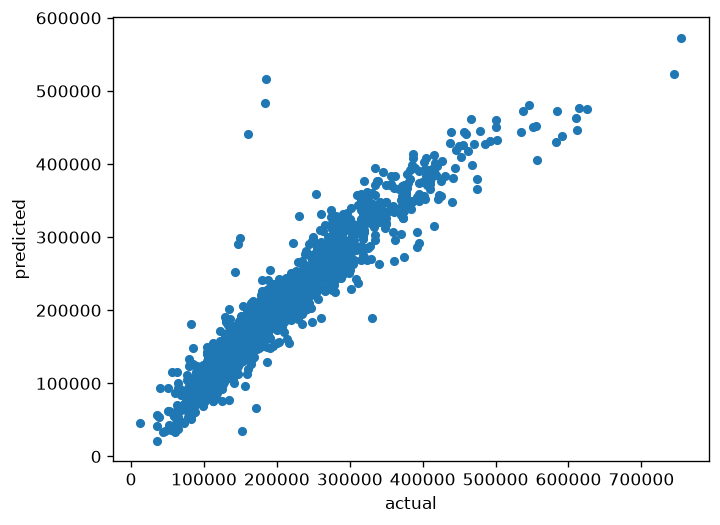

In [47]:
target.plot.scatter(x='actual', y='predicted')


## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [48]:
df = pd.read_csv('https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv')
print(df.head().to_string())


   Unnamed: 0                emp_title  emp_length state homeownership  annual_income  verified_income  debt_to_income  annual_income_joint verification_income_joint  debt_to_income_joint  delinq_2y  months_since_last_delinq  earliest_credit_line  inquiries_last_12m  total_credit_lines  open_credit_lines  total_credit_limit  total_credit_utilized  num_collections_last_12m  num_historical_failed_to_pay  months_since_90d_late  current_accounts_delinq  total_collection_amount_ever  current_installment_accounts  accounts_opened_24m  months_since_last_credit_inquiry  num_satisfactory_accounts  num_accounts_120d_past_due  num_accounts_30d_past_due  num_active_debit_accounts  total_debit_limit  num_total_cc_accounts  num_open_cc_accounts  num_cc_carrying_balance  num_mort_accounts  account_never_delinq_percent  tax_liens  public_record_bankrupt        loan_purpose application_type  loan_amount  term  interest_rate  installment grade sub_grade issue_month loan_status initial_listing_status dis

                                   count unique                 top  freq           mean            std      min      25%       50%       75%        max
emp_length                        7358.0    NaN                 NaN   NaN       5.930688       3.696128      0.0      2.0       6.0      10.0       10.0
state                               8000     50                  CA  1055            NaN            NaN      NaN      NaN       NaN       NaN        NaN
homeownership                       8000      3            MORTGAGE  3828            NaN            NaN      NaN      NaN       NaN       NaN        NaN
annual_income                     8000.0    NaN                 NaN   NaN   79214.223659   65308.295377      0.0  45000.0   65000.0   95000.0  2300000.0
verified_income                     8000      3     Source Verified  3338            NaN            NaN      NaN      NaN       NaN       NaN        NaN
debt_to_income                    7981.0    NaN                 NaN   NaN      19.

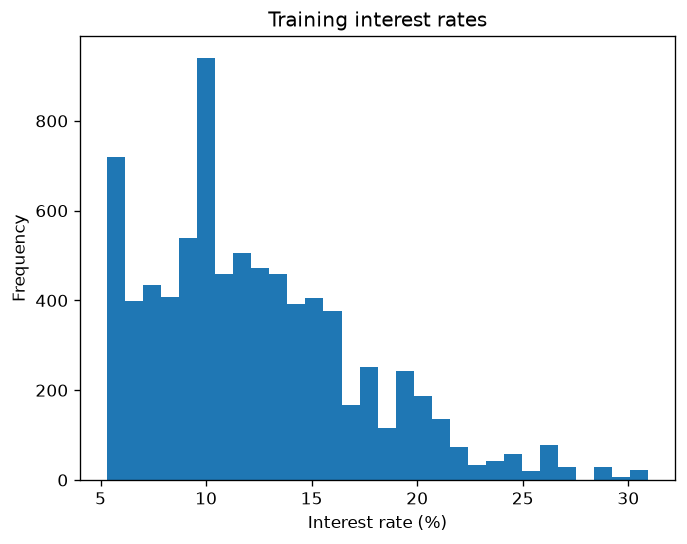

In [ ]:
loan_features = ["emp_length", "state", "homeownership", "annual_income", "verified_income", "debt_to_income", "annual_income_joint", "verification_income_joint", "debt_to_income_joint", "delinq_2y", "months_since_last_delinq", "earliest_credit_line", "inquiries_last_12m", "total_credit_lines", "open_credit_lines", "total_credit_limit", "total_credit_utilized", "num_collections_last_12m", "num_historical_failed_to_pay", "months_since_90d_late", "current_accounts_delinq", "total_collection_amount_ever", "current_installment_accounts", "accounts_opened_24m", "months_since_last_credit_inquiry", "num_satisfactory_accounts", "num_accounts_120d_past_due", "num_accounts_30d_past_due", "num_active_debit_accounts", "total_debit_limit", "num_total_cc_accounts", "num_open_cc_accounts", "num_cc_carrying_balance", "num_mort_accounts", "account_never_delinq_percent", "tax_liens", "public_record_bankrupt", "loan_purpose", "application_type", "loan_amount", "term"]
loans = df.dropna(subset=["interest_rate"])
loan_train, loan_test = train_test_split(loans, test_size=0.2, random_state=5544)
print(loan_train[loan_features + ["interest_rate"]].describe(include="all").T.to_string())
print("Missing values:")
print(loan_train[loan_features].isna().sum().sort_values(ascending=False).to_string())
loan_train["interest_rate"].plot.hist(bins=30, title="Training interest rates")
plt.xlabel("Interest rate (%)")
plt.show()

X_train = loan_train[loan_features].copy()
X_test = loan_test[loan_features].copy()
y_train = loan_train["interest_rate"]
y_test = loan_test["interest_rate"]
log_columns = ["annual_income", "annual_income_joint", "loan_amount", "total_credit_limit", "total_credit_utilized", "total_debit_limit", "total_collection_amount_ever"]
for column in log_columns:
    X_train[column] = np.log1p(X_train[column])
    X_test[column] = np.log1p(X_test[column])

numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
loan_preprocess = ColumnTransformer([
    ("numeric", numeric, make_column_selector(dtype_include=np.number)),
    ("categorical", categorical, make_column_selector(dtype_include=object))
])
loan_cv = KFold(n_splits=5, shuffle=True, random_state=5544)
loan_models = {
    "Linear regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 100, 1000]}),
    "LASSO": (Lasso(max_iter=20000), {"model__alpha": [0.001, 0.01, 0.1, 1]}),
    "Elastic net": (ElasticNet(max_iter=20000), {"model__alpha": [0.001, 0.01, 0.1, 1], "model__l1_ratio": [0.2, 0.5, 0.8]})
}
loan_searches = {}
rows = []
for name, (model, grid) in loan_models.items():
    pipeline = Pipeline([("preprocessing", loan_preprocess), ("model", model)])
    search = GridSearchCV(pipeline, grid, cv=loan_cv, scoring="neg_root_mean_squared_error")
    search.fit(X_train, y_train)
    loan_searches[name] = search
    rows.append({"Model": name, "CV RMSE": -search.best_score_, "Parameters": search.best_params_})

loan_results = pd.DataFrame(rows).sort_values("CV RMSE")
print(loan_results.to_string(index=False))
best_name = loan_results.iloc[0]["Model"]
best_loan_model = loan_searches[best_name].best_estimator_
predictions = best_loan_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, predictions))
print("Selected model:", best_name)
print("Best parameters:", loan_searches[best_name].best_params_)
print(f"Held-out test RMSE: {test_rmse:.3f} percentage points")


Elastic net had the lowest CV RMSE at about 4.00, using alpha = 0.01 and l1_ratio = 0.5. Its test RMSE was 3.946 percentage points. Ridge and LASSO were close, and all three slightly improved on linear regression. I left out payment and loan grading fields to focus on applicant and loan-request information.